# Importing Necessary Libraries

In [1]:
# Loading the necessary libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import re
import nltk
from nltk.corpus import stopwords
from imblearn.over_sampling import SMOTE
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.optimizers import Adam
from wordcloud import WordCloud
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split
from tensorflow.keras.regularizers import l2

In [3]:
!pip install kagglehub
import kagglehub

In [4]:
# Download latest version
file_path = kagglehub.dataset_download("karkavelrajaj/amazon-sales-dataset") + '/amazon.csv'

# Loading the Dataset
df = pd.read_csv(file_path)

In [5]:
df.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [6]:
seed_value = 42
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

In [7]:
df.columns

Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'user_name', 'review_id', 'review_title',
       'review_content', 'img_link', 'product_link'],
      dtype='object')

In [8]:
df.describe()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
count,1465,1465,1465,1465,1465,1465,1465,1463,1465,1465,1465,1465,1465,1465,1465,1465
unique,1351,1337,211,550,449,92,28,1143,1293,1194,1194,1194,1194,1212,1412,1465
top,B07JW9H4J1,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,50%,4.1,"9,378",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...","$@|\|TO$|-|,Sethu madhav,Akash Thakur,Burger P...","R3F4T5TRYPTMIG,R3DQIEC603E7AY,R1O4Z15FD40PV5,R...","Worked on iPhone 7 and didn’t work on XR,Good ...","I am not big on camera usage, personally. I wa...",https://m.media-amazon.com/images/I/413sCRKobN...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
freq,3,5,233,53,120,56,244,9,6,10,10,10,10,8,3,1


# Data Cleaning

In [10]:
# Extract relevant columns
texts = df["review_content"].astype(str).fillna("").tolist()  # Convert reviews to string & handle missing values

# Convert rating to numeric, replacing errors with NaN
df["rating"] = pd.to_numeric(df["rating"], errors='coerce')

# Fill NaN ratings with median rating (or any appropriate value)
df["rating"].fillna(df["rating"].median(), inplace=True)

# Convert to binary sentiment labels (positive if rating >= 3, negative otherwise)
ratings = (df["rating"] >= 4).astype(int).tolist()


/var/folders/9p/hmb8k3hd6dz2ch2z_h0fv_d00000gn/T/ipykernel_9089/379718679.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["rating"].fillna(df["rating"].median(), inplace=True)


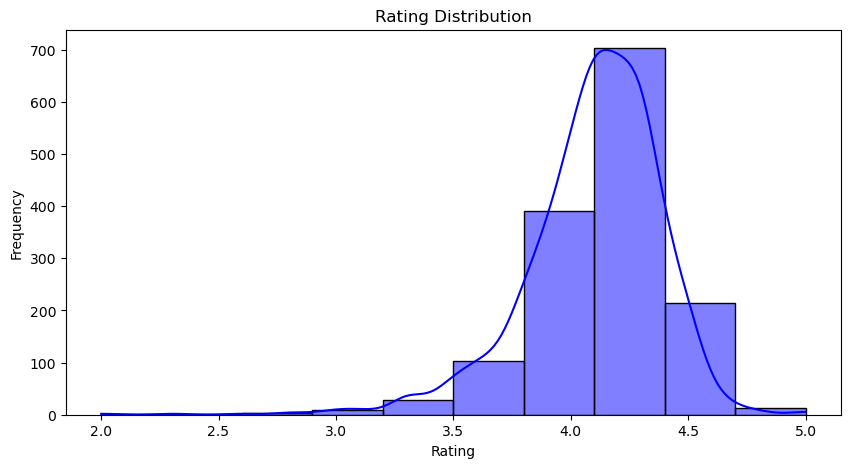

In [11]:
# Rating Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['rating'].dropna(), bins=10, kde=True, color="blue")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

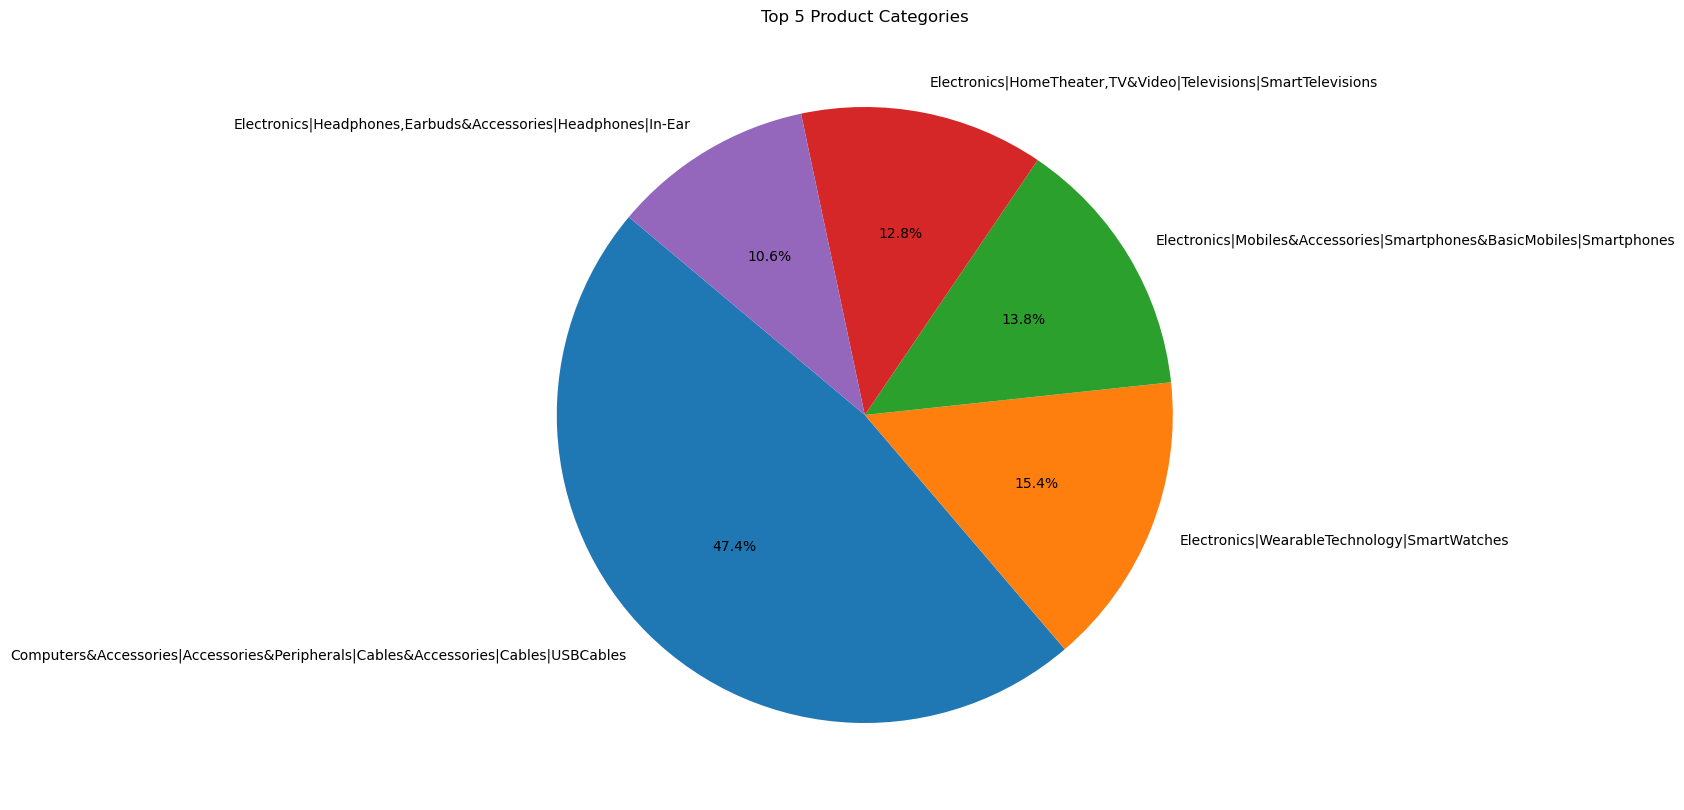

In [12]:
# Get the top 5 product categories
top_categories = df['category'].value_counts().nlargest(5)

# Pie chart
plt.figure(figsize=(10, 10))
plt.pie(top_categories, labels=top_categories.index, autopct='%1.1f%%', startangle=140)
plt.title("Top 5 Product Categories")
plt.show()

In [13]:
# Extract relevant columns
texts = df["review_content"].astype(str).fillna("").tolist()  # Convert reviews to string & handle missing values
ratings = df["rating"].fillna(0).astype(float)

In [14]:
# Combine all reviews
all_reviews = " ".join(df['review_content'].dropna())

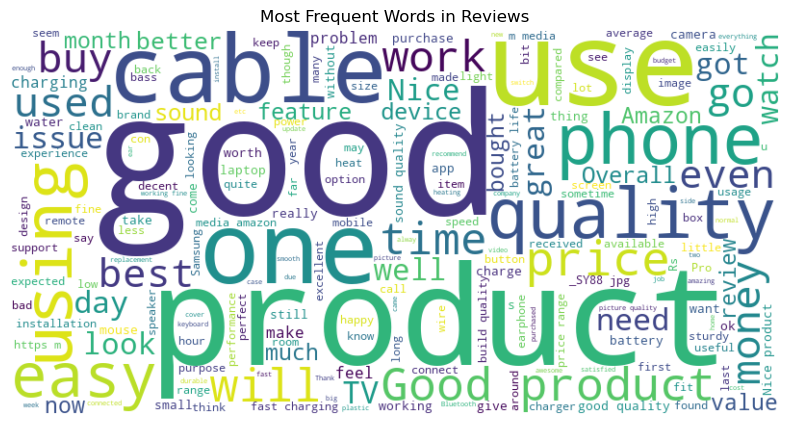

In [15]:
# Generate WordCloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_reviews)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Reviews")
plt.show()

In [16]:
# Convert ratings to binary sentiment labels (1 = positive, 0 = negative)
labels = np.where(ratings >= 4, 1, 0)  # Positive if rating >= 4, else Negative

In [17]:
# Tokenization and Padding
max_words = 5000  # Max vocabulary size
max_len = 100  # Max sequence length for LSTM

In [18]:
tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
word_index = tokenizer.word_index
vocab_size = len(word_index) + 1  # Add 1 for OOV token

In [19]:
sequences = tokenizer.texts_to_sequences(texts)
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [20]:
os.system('curl -L -O http://nlp.stanford.edu/data/glove.6B.zip')
os.system('unzip -o "glove.6B.zip"')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0   308    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0   346    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  822M  100  822M    0     0  5246k      0  0:02:40  0:02:40 --:--:-- 5108k


Archive:  glove.6B.zip
  inflating: glove.6B.50d.txt        
  inflating: glove.6B.100d.txt       
  inflating: glove.6B.200d.txt       
  inflating: glove.6B.300d.txt       


0

In [21]:
glove_path = "glove.6B.100d.txt"  # Path to pretrained embeddings
embedding_dim = 100  # GloVe embedding size

In [22]:
# Load GloVe word embeddings
embeddings_index = {}
with open(glove_path, encoding="utf-8") as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype="float32")
        embeddings_index[word] = coefs

In [23]:
# Create Embedding Matrix
word_index = tokenizer.word_index
num_words = min(max_words, len(word_index) + 1)
embedding_matrix = np.zeros((num_words, embedding_dim))

In [24]:
for word, i in word_index.items():
    if i < max_words:  # Use only top max_words
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

In [25]:
# Define model
lstm_model = Sequential()

# Explicitly define input shape
lstm_model.add(Embedding(input_dim=num_words, output_dim=embedding_dim, weights=[embedding_matrix],
                         input_length=max_len, trainable=True))

lstm_model.add(SpatialDropout1D(0.2))

# Explicit input shape for LSTM layer
lstm_model.add(LSTM(64, return_sequences=False, input_shape=(max_len, embedding_dim)))

lstm_model.add(Dropout(0.3))
# Pass kernel_regularizer directly to the Dense layer
lstm_model.add(Dense(1, activation="sigmoid"))

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [26]:
# Compile the model
lstm_model.compile(loss="binary_crossentropy", optimizer=Adam(learning_rate=0.001), metrics=["accuracy"])

# Force model building
lstm_model.build(input_shape=(None, max_len))

# Print summary
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 100)       │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 100, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 542,305 (2.07 MB)

 Trainable params: 542,305 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Split into training and validation sets (80-20 split)
split = int(0.5 * len(padded_sequences))
X_train, X_val = padded_sequences[:split], padded_sequences[split:]
y_train, y_val = labels[:split], labels[split:]

In [28]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)
X_val,y_val=rus.fit_resample(X_val,y_val)

In [29]:
# Train LSTM model
lstm_model.fit(X_train_resampled, y_train_resampled, epochs=10, batch_size=32, validation_data=(X_val, y_val))

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.5007 - loss: 0.7025 - val_accuracy: 0.5541 - val_loss: 0.6929
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5863 - loss: 0.6985 - val_accuracy: 0.5412 - val_loss: 0.6890
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6237 - loss: 0.6696 - val_accuracy: 0.5464 - val_loss: 0.6897
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6284 - loss: 0.6416 - val_accuracy: 0.5490 - val_loss: 0.6949
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6774 - loss: 0.6248 - val_accuracy: 0.5206 - val_loss: 0.7044
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6897 - loss: 0.6052 - val_accuracy: 0.5206 - val_loss: 0.7184
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7197 - loss: 0.5683 - val_accuracy: 0.5103 - val_loss: 0.7536
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7056 - loss: 0.5461 - val_accuracy: 0.5361 - v

In [30]:
# Predict on training set
y_pred_prob = lstm_model.predict(X_train_resampled)
y_pred = (y_pred_prob > 0.5).astype(int)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [31]:
#Print Classification Report for training set
print("Classification Report for training set:")
print(classification_report(y_train_resampled, y_pred))

Classification Report for training set:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       160
           1       0.87      0.82      0.85       160

    accuracy                           0.85       320
   macro avg       0.85      0.85      0.85       320
weighted avg       0.85      0.85      0.85       320



In [32]:
# Predict on validation set
y_pred_prob = lstm_model.predict(X_val)
y_pred = (y_pred_prob > 0.5).astype(int)  # Convert probabilities to binary labels

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [33]:
# Print Classification Report for validation set
print("Classification Report for validatio set:")
print(classification_report(y_val, y_pred))

Classification Report for validatio set:
              precision    recall  f1-score   support

           0       0.53      0.49      0.51       194
           1       0.53      0.57      0.55       194

    accuracy                           0.53       388
   macro avg       0.53      0.53      0.53       388
weighted avg       0.53      0.53      0.53       388



# Aspect-Based Sentiment Analysis

In [35]:
!pip install vaderSentiment

In [36]:
import torch
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import pipeline

In [37]:
# Selecting relevant columns
df_rev = df[['review_content']]

In [38]:
# Define aspects
aspects = ["price", "quality", "delivery"]

In [39]:
# Initializing sentiment analyzers
vader = SentimentIntensityAnalyzer()
bert_sentiment = pipeline("sentiment-analysis")

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use mps:0


In [40]:
# Function to extract aspect-based sentiment
def analyze_aspect_sentiment(text):
    aspect_sentiments = {}
    # Truncate text to BERT's max sequence length to avoid RuntimeError
    max_length = 512  # You can adjust this based on your BERT model
    text = text[:max_length]  # Truncate longer reviews

    for aspect in aspects:
        if aspect in text.lower():
            # TextBlob Sentiment
            blob_score = TextBlob(text).sentiment.polarity

            # VADER Sentiment
            vader_score = vader.polarity_scores(text)['compound']

            # BERT Sentiment
            bert_result = bert_sentiment(text)[0]
            bert_label = bert_result['label']
            bert_score = bert_result['score'] if bert_label == 'POSITIVE' else -bert_result['score']

            # Average sentiment score
            avg_sentiment = (blob_score + vader_score + bert_score) / 3
            aspect_sentiments[aspect] = avg_sentiment

    return aspect_sentiments if aspect_sentiments else None

In [41]:
# Apply ABSA
df_new=df_rev.copy()
df_new['aspect_sentiments'] = df_rev['review_content'].apply(analyze_aspect_sentiment)

In [42]:
# Filter out rows without aspect mentions
df_new= df_new.dropna(subset=['aspect_sentiments'])

In [43]:
# Expand aspect sentiment dictionary into columns
aspect_df = df_new['aspect_sentiments'].apply(pd.Series)

In [44]:
# Merge with original DataFrame, using suffixes to avoid overlapping column names
df_new = df_new.join(aspect_df, lsuffix='_caller', rsuffix='_other').drop(columns=['aspect_sentiments'])

In [45]:
# Convert sentiment scores to human-readable labels
def convert_to_label(score):
    """Convert sentiment score to a human-readable label."""
    # Check if score is already a label (str), return as is if True
    if isinstance(score, str):  # Check the data type to see if it's a string
        return score
    elif pd.isna(score):  # If NaN, return 'Not Mentioned'
        return "Not Mentioned"
    elif score > 0.2:
        return "Positive"
    elif score < -0.2:
        return "Negative"
    else:
        return "Neutral"

# Apply the function to all aspect columns
df_new[['quality', 'price', 'delivery']] = df_new[['quality', 'price', 'delivery']].applymap(convert_to_label)

/var/folders/9p/hmb8k3hd6dz2ch2z_h0fv_d00000gn/T/ipykernel_9089/4248557291.py:17: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_new[['quality', 'price', 'delivery']] = df_new[['quality', 'price', 'delivery']].applymap(convert_to_label)


In [46]:
# Save processed data
df_new.to_csv("aspect_based_sentiment_results.csv", index=False)

In [47]:
df_new.head(5)

,review_content,quality,price,delivery
0,Looks durable Charging is fine tooNo complains...,Positive,Not Mentioned,Not Mentioned
1,I ordered this cable to connect my phone to An...,Positive,Positive,Not Mentioned
3,"Good product,long wire,Charges good,Nice,I bou...",Not Mentioned,Neutral,Not Mentioned
4,"Bought this instead of original apple, does th...",Positive,Not Mentioned,Not Mentioned
6,Build quality is good and it is comes with 2 y...,Positive,Not Mentioned,Not Mentioned


In [48]:
# Melt dataframe for easier visualization
df_melted = df_new.melt(id_vars=['review_content'], value_vars=['quality', 'price', 'delivery'],
                     var_name="Aspect", value_name="Sentiment")

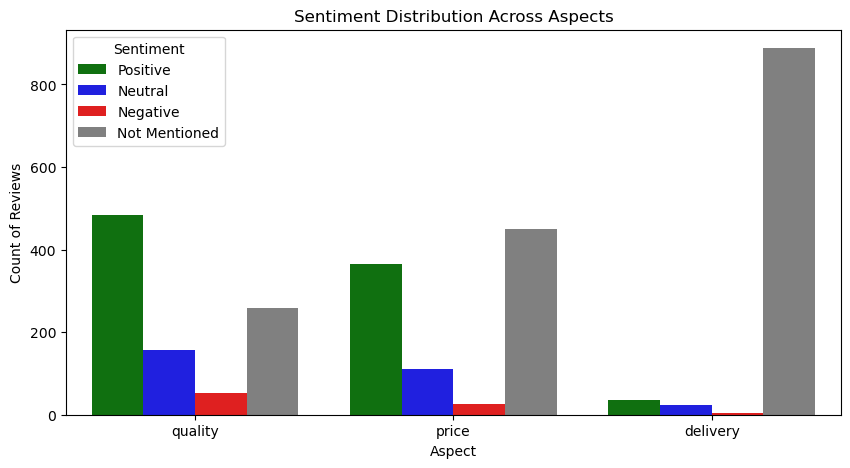

In [49]:
# Countplot for sentiment distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df_melted, x="Aspect", hue="Sentiment",
              order=["quality", "price", "delivery"],
              hue_order=["Positive", "Neutral", "Negative", "Not Mentioned"],
              palette={"Positive": "green", "Neutral": "blue", "Negative": "red", "Not Mentioned": "gray"})
plt.title("Sentiment Distribution Across Aspects")
plt.xlabel("Aspect")
plt.ylabel("Count of Reviews")
plt.legend(title="Sentiment")
plt.show()

# Hybrid Recommendation System

In [51]:
!pip install surprise

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [52]:
import pandas as pd
from surprise import Dataset, Reader
from surprise.model_selection import train_test_split
from surprise import SVD
from surprise import accuracy
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse.linalg import svds

In [53]:
df.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [54]:
# Mergig both the dataframes Ensure both dataframes align on the index
df = df.reset_index(drop=True)
data_new = df_new.reset_index(drop=True)

# Merge both dataframes
df_merged = pd.concat([df, data_new.iloc[:, 1:]], axis=1)  # Skip first column (review_content) in data_new to avoid duplication

# Display the merged dataframe
df_merged.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,quality,price,delivery
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,Positive,Not Mentioned,Not Mentioned
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,Positive,Positive,Not Mentioned
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,Not Mentioned,Neutral,Not Mentioned
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,Positive,Not Mentioned,Not Mentioned
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,Positive,Not Mentioned,Not Mentioned


In [55]:
#Converting Sentiment Labels to Numeric Scores
sentiment_mapping = {"Positive": 1, "Neutral": 0, "Negative": -1, "Not Mentioned": 0}

df_merged["quality_score"] = df_merged["quality"].map(sentiment_mapping)
df_merged["price_score"] = df_merged["price"].map(sentiment_mapping)
df_merged["delivery_score"] = df_merged["delivery"].map(sentiment_mapping)

In [56]:
#Computing an Overall Sentiment Score
df_merged["sentiment_score"] = df_merged[["quality_score", "price_score", "delivery_score"]].sum(axis=1)

#Prioritizing Highly Rated Products with Positive Sentiment
df_filtered = df_merged[df_merged["sentiment_score"] > 0]  # Select products with positive sentiment
df_filtered = df_filtered.sort_values(by=["sentiment_score", "rating"], ascending=[False, False])


In [57]:
#Selectig Top N Recommended Products
top_n = 15
recommended_products = df_filtered[["product_name", "rating", "sentiment_score"]].head(top_n)

# Displaying Recommended Products
print(recommended_products)

                                          product_name  rating  \
821  Lenovo 400 Wireless Mouse, 1200DPI Optical Sen...     4.4   
190  VW 60 cm (24 inches) Premium Series HD Ready L...     4.2   
99   Wayona Type C to Lightning MFI Certified 20W F...     4.1   
743  Amazon Basics Magic Slate 8.5-inch LCD Writing...     4.1   
834  Kingston DataTraveler Exodia DTX/32 GB Pen Dri...     4.1   
817  TVARA LCD Writing Tablet 8.5 Inch E-Note Pad L...     4.0   
477  Tecno Spark 9 (Sky Mirror, 6GB RAM,128GB Stora...     3.8   
506  PTron Newly Launched Force X10 Bluetooth Calli...     3.3   
174  Syncwire LTG to USB Cable for Fast Charging Co...     5.0   
459  Spigen EZ Fit Tempered Glass Screen Protector ...     4.7   
137  10k 8k 4k HDMI Cable, Certified 48Gbps 1ms Ult...     4.6   
853  Logitech Pebble M350 Wireless Mouse with Bluet...     4.6   
88   Lapster 65W compatible for OnePlus Dash Warp C...     4.5   
98   TP-Link UE300 USB 3.0 to RJ45 Gigabit Ethernet...     4.5   
146  Amazo